In [6]:
from anemone.forwards import Forward, ForwardLaplace3
from anemone.experiment import Loop, Receiver, Waveform
import torch
import matplotlib.pyplot as plt
import numpy as np


In [307]:
t = torch.logspace(-7, -4, 51)
tx,rx,wv = Loop.square(40), Receiver(), Waveform.example()

# wv = Waveform(torch.tensor([-1.e-3, -0.9e-3, 0, 0.9e-8]), torch.tensor([0, 1, 1, 0]))

fwr = Forward(tx,rx,t)

In [308]:
from anemone.transforms import Hankel, invFourier, CubicSpline, invLaplace
from anemone.physics import refl_transverse_electric as rte, freespace_u0 as u0, colecole, mpa2colecole, colecole2mpa
from anemone import constants as c
from anemone.experiment import integrate_around_loop

class Forward2(Forward):
    def calc_ft(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]

            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lamda = wave_length[None, None, :]
                
                tmp_u0 = u0(self.omega, self.lamda)
                intg = torch.exp(-tmp_u0*self.pfield_dz)
                intg += rte(self.sigma, self.thick, self.omega, self.lamda)*torch.exp(-tmp_u0*self.sfield_dz)
                
                intg *= self.lamda**2 / tmp_u0
                
                if self.waveform is not None:
                    intg /= -1j*self.omega
                else:
                    intg *= self.omega
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                return intg/c.fourpi
            
            hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
            res = integrate_around_loop(self.source, self.receiver, hkl1)
            if self.waveform is None:
                res /= self.omega.squeeze()
            return res.T
        
        return invFourier(frq_integrand, smp_per_decade=8, range=(self.tmin, self.tmax), device=self.device, tolerance=self.tolerance)
    
# Forward2 = Forward

In [333]:
from anemone.forwards import ForwardLaplace, ForwardLaplace5
from anemone.transforms import Hankel, invFourier, CubicSpline, invLaplace
from anemone.physics import refl_transverse_electric as rte, freespace_u0 as u0, colecole, mpa2colecole, colecole2mpa
from anemone import constants as c
from anemone.experiment import integrate_around_loop

class invLaplace2(invLaplace):
    def integral(self, t):
        q = -(c.log2 / t**2)[:, None]
        qi = (q*self.i).flatten()
        respt1 = self.func(qi)
        respt1 = respt1.reshape(respt1.shape[:-1]+t.shape+self.i.shape)
        respt1[..., :,:] *= q
        if respt1.dtype != self.v.dtype:
            self.v = self.v.to(respt1.dtype)
        res = respt1@self.v            
        return res        

class Forward2(ForwardLaplace):
    def calc_ft(self):
        def wvlngth_integrand(wave_length):
            lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                omega = -1j*s[None, None, :]
                
                if self.tmp_u0     is None: self.tmp_u0 = u0(omega, lmb)
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz) / self.tmp_u0
                if self.pfield     is None: self.pfield     = torch.exp(-self.tmp_u0*self.pfield_dz) / self.tmp_u0

                intg  = self.pfield
                intg += rte(self.sigma, self.thick, omega, lmb)*self.sfield_rte

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)

                if self.waveform is not None:
                    intg /= -1j*omega

                return intg
            cbft = invLaplace2(s_integrand, device=self.device, n_coefficients=8)
            res  = cbft(self.t_eval)
            res *= lmb**2 / c.fourpi
            return res.squeeze().swapaxes(-2,-1)

        hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
        res = integrate_around_loop(self.source, self.receiver, hkl1)
        return CubicSpline(self.t_eval, res, transform=torch.log10, integrate=False)
    
# Forward2 = Forward

In [ ]:
from anemone.transforms import Hankel, invFourier, CubicSpline, invLaplace
from anemone.physics import refl_transverse_electric as rte, freespace_u0 as u0, colecole, mpa2colecole, colecole2mpa
from anemone import constants as c
from anemone.experiment import integrate_around_loop

class Forward2(Forward):
    def calc_ft(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]

            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lamda = wave_length[None, None, :]
                
                tmp_u0 = u0(self.omega, self.lamda)
                intg = torch.exp(-tmp_u0*self.pfield_dz)
                intg += rte(self.sigma, self.thick, self.omega, self.lamda)*torch.exp(-tmp_u0*self.sfield_dz)
                
                intg *= self.lamda**2 / tmp_u0
                
                if self.waveform is not None:
                    intg /= -1j*self.omega
                else:
                    intg *= self.omega
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                return intg/c.fourpi
            
            hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
            res = integrate_around_loop(self.source, self.receiver, hkl1)
            if self.waveform is None:
                res /= self.omega.squeeze()
            return res.T
        
        return invFourier(frq_integrand, smp_per_decade=8, range=(self.tmin, self.tmax), device=self.device, tolerance=self.tolerance)
    
# Forward2 = Forward

In [338]:
rho = torch.tensor([40, 40, 40])
thick = torch.tensor([20, 40])

In [339]:
fwr = Forward2(tx,rx,t)
dbdt = fwr(rho, thick)

In [340]:
fwr = ForwardLaplace5(tx,rx,t)
dbdt = fwr(rho, thick)

In [341]:
fwr0 = Forward(tx,rx,t)
dbdt0 = fwr0(rho, thick)

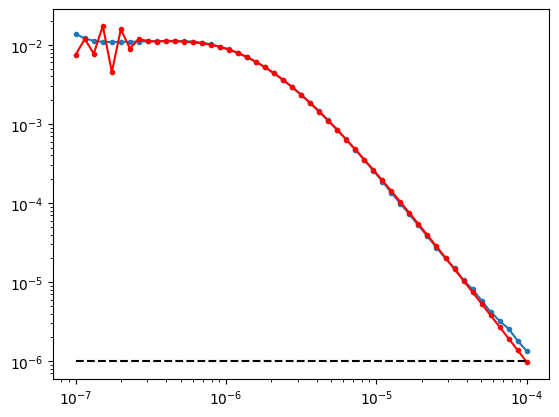

In [342]:
plt.figure()
plt.loglog(t, dbdt.numpy(), '.-')
plt.loglog(t, dbdt0.numpy(), 'r.-')
plt.loglog(t, torch.ones_like(t)*1e-6, 'k--')
